# Motor Parameter Identification

Robotics Assignment 1

This notebook uses two step recordings from each motor and one square-wave recording from each motor. The wheels were lifted so they could spin freely.

The main result is that using different measured values at each motor power predicts the square wave better than using one average set of values. The tables and plots below show both approaches.

Battery readings were taken after testing: 11.4 V for the M3 step tests and both square waves, and 11.3 V for the M4 step tests.


In [1]:
from pathlib import Path
import zipfile

ROOT=Path.cwd()
if not (ROOT/'motor_data').is_dir() and (ROOT/'assignment1'/'motor_data').is_dir():
    ROOT=ROOT/'assignment1'
required=[f'steps_M{motor}_run{run}.txt' for motor in (3,4) for run in (1,2)]
required += [f'signal_M{motor}_square_run1.txt' for motor in (3,4)]
if not all((ROOT/'motor_data'/name).is_file() for name in required):
    package=ROOT/'analysis_data.zip'
    if not package.exists():
        raise FileNotFoundError('Upload analysis_data.zip or place motor_data beside the notebook.')
    with zipfile.ZipFile(package) as archive:
        for name in required+['battery.txt']:
            target=ROOT/'motor_data'/name
            target.parent.mkdir(parents=True,exist_ok=True)
            if not target.exists():
                target.write_bytes(archive.read('motor_data/'+name))
DATA=ROOT/'motor_data'
OUTPUT=ROOT/'analysis_outputs'
FIGURES=OUTPUT/'figures'
FIGURES.mkdir(parents=True,exist_ok=True)
get_ipython().run_line_magic('matplotlib','inline')


## What the model means

- **PWM** is the motor-power command, from -100% to +100%. Its sign sets the rotation direction.
- **Angle**, $\theta$, is how far the wheel has rotated, measured in radians.
- **Speed**, $\omega$, is how fast the wheel rotates, measured in radians per second.
- **Final speed**, $\omega_{ss}$, is the speed reached after acceleration.
- **Time constant**, $T_m$, is the time needed to reach about 63% of the final speed.
- **$k_e$** tells how much voltage the model needs for one unit of speed.

The assignment uses

$$\frac{d\omega}{dt}=\frac{U}{T_m k_e}-\frac{\omega}{T_m},\qquad \frac{d\theta}{dt}=\omega.$$

For a constant voltage and a motor starting from rest, this gives

$$\omega(t)=\omega_{ss}(1-e^{-t/T_m}),\qquad \omega_{ss}=U/k_e.$$

Adding up the speed over time gives the angle equation used to fit the data:

$$\theta(t)=\int_0^t\omega(s)\,ds=\omega_{ss}[t-T_m+T_m e^{-t/T_m}].$$

This assumes negligible motor inductance, friction proportional to speed, constant load, and constant battery voltage during a run. The measurements let us check how well these assumptions work.


## Calculation functions

This cell defines the calculations used below.

In [2]:
from pathlib import Path
import html
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.integrate import odeint
from IPython.display import HTML, Markdown, display

plt.rcParams.update({'figure.dpi':105, 'savefig.dpi':170, 'font.size':10,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'axes.grid':True, 'grid.alpha':0.19})
COLORS={(3,1):'#0072B2',(3,-1):'#009E73',(4,1):'#D55E00',(4,-1):'#9C5AAB'}
MODEL_NAMES={'simple':'Simple model','power_levels':'Model using each power level'}
MODEL_COLORS={'simple':'#0072B2','power_levels':'#009E73'}

def load_record(path):
    # Read one recording and express its time and angle relative to the first sample.
    # Columns are angle in degrees, time in milliseconds, and motor power in percent.
    a=np.loadtxt(path,delimiter=',',ndmin=2)
    if a.shape[1]!=3 or not np.isfinite(a).all():
        raise ValueError(f'Expected angle, time and motor power in {path.name}')
    if not np.all(np.diff(a[:,1])>0):
        raise ValueError(f'Times are out of order in {path.name}')
    # Convert to seconds and radians, keeping the original measurements in raw.
    return dict(name=path.name,raw=a,t=(a[:,1]-a[0,1])/1000,
                theta=np.deg2rad(a[:,0]-a[0,0]),pwm=a[:,2],
                first_clock_ms=float(a[0,1]),first_angle_deg=float(a[0,0]))

def table(rows, columns=None, title=None, digits=4):
    # Format the results as a readable table; this does not change the calculations.
    """Display a compact table without requiring pandas."""
    if not rows:
        return
    columns = columns or [(key, key) for key in rows[0]]
    def fmt(value):
        # Round numbers for display and label missing or unreliable values clearly.
        if isinstance(value, (float, np.floating)):
            return 'Not measured' if not np.isfinite(value) else f'{value:.{digits}g}'
        return str(value)
    head = ''.join(f'<th>{html.escape(label)}</th>' for _, label in columns)
    body = ''.join('<tr>'+''.join(f'<td>{html.escape(fmt(row.get(key, "")))}</td>'
                                for key, _ in columns)+'</tr>' for row in rows)
    caption = f'<h4>{html.escape(title)}</h4>' if title else ''
    display(HTML(caption+'<div style="overflow-x:auto"><table style="border-collapse:collapse;font-size:12px">'
                 '<style>th,td{padding:5px 8px;border:1px solid #ddd}th{background:#eee}</style>'
                 f'<thead><tr>{head}</tr></thead><tbody>{body}</tbody></table></div>'))

def save_figure(fig, name, caption=None):
    # Save the graph, show it in the notebook, then release the figure from memory.
    fig.savefig(FIGURES / name, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close(fig)
    if caption:
        display(Markdown(caption))

def segments(record):
    # Split the recording into sections where motor power stays constant.
    a = record['raw']
    # A new section begins at the first sample and whenever the power changes.
    starts = np.r_[0, np.flatnonzero(np.diff(a[:, 2]) != 0)+1]
    ends = np.r_[starts[1:], len(a)]
    return [dict(pwm=float(a[s, 2]), start=int(s), end=int(e), raw=a[s:e],
                 t=(a[s:e, 1]-a[s, 1])/1000,
                 theta=np.deg2rad(a[s:e, 0]-a[s, 0])) for s, e in zip(starts, ends)]

def angle_model(t, speed, T_m):
    # Predict angle for a motor that starts at rest and approaches a steady speed.
    # Numerically stable form of speed*(t - T_m + T_m*exp(-t/T_m)).
    return speed * (t + T_m*np.expm1(-t/T_m))

def fit_steps(record, motor, run):
    # Find the final speed and response time that best reproduce each powered step.
    rows = []
    for seg in segments(record):
        pwm, t, theta = seg['pwm'], seg['t'], seg['theta']
        if pwm == 0:
            continue
        # Use the last half-second to make a starting guess for the final speed.
        initial_speed = float(np.polyfit(t[t >= t[-1]-.5], theta[t >= t[-1]-.5], 1)[0])
        dt = float(np.median(np.diff(t)))
        # A change of no more than one encoder degree is too small to fit reliably.
        if np.ptp(theta) <= np.deg2rad(1):
            speed = 0.; T = se_speed = se_T = np.nan
            prediction = np.zeros_like(theta); status = 'No clear movement'
        else:
            # Keep speed in the commanded direction and response time between 0.0001 and 2 s.
            low, high = ([0., .0001], [100., 2.]) if pwm > 0 else ([-100., .0001], [0., 2.])
            # Adjust speed and response time until the predicted angle follows the measurements.
            popt, pcov = optimize.curve_fit(angle_model, t, theta,
                p0=[np.clip(initial_speed, low[0]+.001, high[0]-.001), .1],
                bounds=(low, high), maxfev=20000)
            speed, T = map(float, popt)
            # These uncertainty estimates come from the fit, not from all possible measurement errors.
            se_speed, se_T = np.sqrt(np.diag(pcov))
            prediction = angle_model(t, speed, T)
            status = 'Faster than sample spacing' if T < dt else 'fit'
            # A result at a fitting limit does not give a reliable response time.
            if T < .00011 or T > 1.999:
                status = 'Time constant not measured'
        rows.append(dict(motor=motor, run=run, pwm=pwm,
                         speed=speed, T=T, se_speed=float(se_speed), se_T=float(se_T),
                         angle_rmse=float(np.sqrt(np.mean((theta-prediction)**2))),
                         median_dt=dt, terminal_speed=initial_speed,
                         samples=len(t), status=status, segment=seg))
    return rows


def moving_average(y, window=3):
    # Reduce small speed fluctuations by averaging neighbouring samples.
    # Centered 3-sample mean with replicated edges; never written back to raw data.
    return np.convolve(np.pad(y, (window//2,window//2), mode='edge'),
                       np.ones(window)/window, mode='valid')


def fit_percentage(actual, predicted):
    # Score the predicted curve against the measurements: 100% means a perfect match.
    # Compare the prediction error with the error from using the measured average.
    # A score of zero matches that baseline; negative scores are worse.
    denominator=np.linalg.norm(actual-np.mean(actual))
    return float(100*(1-np.linalg.norm(actual-predicted)/denominator)) if denominator>0 else np.nan

def signal_metrics(record, prediction):
    # Calculate angle and speed errors for the square-wave prediction.
    # Estimate speed from angle changes using the actual recorded time intervals.
    theta=record['theta']; omega=np.gradient(theta,record['t'])
    # Apply the same smoothing to measured and predicted speed for a fair comparison.
    smooth=moving_average(omega); predicted_smooth=moving_average(prediction[:,0])
    # Identify the powered part so it can also be scored separately from coasting.
    active=np.flatnonzero(record['pwm']!=0)
    mask=np.arange(len(theta));mask=(mask>=active[0])&(mask<=active[-1])
    error=theta-prediction[:,1]; worst=int(np.argmax(np.abs(error)))
    return dict(angle_rmse=float(np.sqrt(np.mean(error**2))),
        angle_fit=fit_percentage(theta,prediction[:,1]),
        active_angle_fit=fit_percentage(theta[mask],prediction[mask,1]),
        speed_rmse_raw=float(np.sqrt(np.mean((omega-prediction[:,0])**2))),
        speed_fit_raw=fit_percentage(omega,prediction[:,0]),
        speed_rmse_smoothed=float(np.sqrt(np.mean((smooth-predicted_smooth)**2))),
        speed_fit_smoothed=fit_percentage(smooth,predicted_smooth),
        max_abs_angle_error=float(abs(error[worst])),worst_error_time_s=float(record['t'][worst]),
        final_angle_error=float(error[-1]))

def repeatability(fits):
    # Compare the two step runs at the same motor power; smaller differences are better.
    rows=[]
    for motor in (3,4):
        for pwm in range(-100,101,10):
            if pwm==0:continue
            a,b=sorted([r for r in fits if r['motor']==motor and r['pwm']==pwm],key=lambda r:r['run'])
            # Divide the difference by the average size of the two values.
            pct=lambda x,y:float(200*abs(x-y)/(abs(x)+abs(y)))
            # Do not compare response times that could not be measured reliably.
            T_difference = (np.nan if any(r['status']=='Time constant not measured' for r in (a,b))
                            else pct(a['T'],b['T']))
            rows.append(dict(motor=motor,pwm=pwm,speed_difference_pct=pct(a['speed'],b['speed']),
                             T_difference_pct=T_difference))
    return rows

def coast_and_reversals(step_records, signal_records):
    # Measure continued rotation after power is removed and delays when reversing.
    coasts=[]; reversals=[]
    for (motor,run),record in step_records.items():
        ss=segments(record)
        for before,seg in zip(ss,ss[1:]):
            # Only use motor-off sections that immediately follow a powered step.
            if not before['pwm'] or seg['pwm']!=0:continue
            t,y=seg['t'],seg['theta']; T=np.nan
            if np.ptp(y)>np.deg2rad(2):
                # Predict the extra angle as the initial speed gradually falls towards zero.
                def coast_angle(t,v0,tc):return -v0*tc*np.expm1(-t/tc)
                initial=np.polyfit(t[:min(6,len(t))],y[:min(6,len(t))],1)[0]
                try:
                    popt,_=optimize.curve_fit(coast_angle,t,y,p0=[initial,.2],
                        bounds=([-100,.001],[100,3]),maxfev=10000)
                    if .0011<popt[1]<2.999:T=float(popt[1])
                except (RuntimeError,ValueError):pass
            coasts.append(dict(motor=motor,run=run,pwm=before['pwm'],
                angle_deg=float(np.rad2deg(y[-1])),T_coast=T))
    for (motor,kind),record in signal_records.items():
        if kind!='square':continue
        velocity=np.gradient(record['theta'],record['t'])
        u=record['pwm'];t=record['t']
        # Find each change of direction and the first sample moving in the new direction.
        for index in np.flatnonzero(u[1:]*u[:-1]<0)+1:
            end=min(index+1+int(.4/np.median(np.diff(t))),len(t))
            matched=[j for j in range(index,end) if np.sign(velocity[j])==np.sign(u[index])]
            delay=t[matched[0]]-t[index] if matched else np.nan
            reversals.append(dict(motor=motor,time_s=float(t[index]),direction=int(np.sign(u[index])),
                                  response_delay_s=float(delay)))
    return coasts,reversals

def build_parameters(fits):
    # Prepare the motor values needed by the simple and power-level models.
    summary=[]; parameters={}
    for motor in (3,4):
        rows=[r for r in fits if r['motor']==motor]
        # Use the available after-testing battery readings for each motor's step recordings.
        battery=11.4 if motor==3 else 11.3
        for sign,direction in [(1,'Forward'),(-1,'Backward')]:
            selected=[r for r in rows if np.sign(r['pwm'])==sign]
            # Find the speed-versus-power trend from 40% to 100%, separately for each direction.
            high_power=[r for r in selected if abs(r['pwm'])>=40]
            power=np.abs([r['pwm'] for r in high_power])
            speed=np.abs([r['speed'] for r in high_power])
            slope,intercept=np.polyfit(power,speed,1)
            # Leave unreliable response times out of the average.
            times=[r['T'] for r in selected if r['status']!='Time constant not measured']
            summary.append(dict(motor=motor,direction=direction,dead_zone='Below 10%; exact value unknown',
                slope=float(slope),intercept=float(intercept),ke=float(battery/100/slope),
                T_mean=float(np.mean(times)),voltage=battery))
        # One speed/voltage value for the simple model, using a line through zero.
        selected=[r for r in rows if abs(r['pwm'])>=40]
        voltage=np.array([r['pwm']*battery/100 for r in selected])
        speed=np.array([r['speed'] for r in selected])
        ke_simple=float(np.dot(voltage,voltage)/np.dot(voltage,speed))
        # Average the two runs at each tested power for the more detailed model.
        levels=np.array(sorted({r['pwm'] for r in rows}))
        speeds=np.array([np.mean([r['speed'] for r in rows if r['pwm']==u]) for u in levels])
        times=np.array([np.mean([r['T'] for r in rows if r['pwm']==u and
                                 r['status']!='Time constant not measured']) for u in levels])
        # Add zero power: target speed is zero and response time comes from the nearby levels.
        levels=np.insert(levels,10,0);speeds=np.insert(speeds,10,0)
        times=np.insert(times,10,np.mean(times[[9,10]]))
        parameters[motor]=dict(T=float(np.mean([r['T'] for r in rows if r['status']!='Time constant not measured'])),
            ke_simple=ke_simple,voltage=battery,pwm_levels=levels,speed_levels=speeds,T_levels=times)
    return summary,parameters


def simulate(record,parameters,model='simple'):
    # Predict speed and angle while following the power commands in the recording.
    time=record['t'];power=record['pwm']
    def change(state,t):
        # Calculate how quickly speed and angle are changing at the current instant.
        # Estimate the command between recorded samples using the neighbouring values.
        u=float(np.interp(t,time,power))
        if model=='simple':
            response_time=parameters['T']
            # Both square-wave recordings use the available 11.4 V battery reading.
            target_speed=11.4*u/100/parameters['ke_simple']
        else:
            # Read speed and response time from the measured power levels, using values
            # between the nearest levels when the requested power is not an exact match.
            target_speed=float(np.interp(u,parameters['pwm_levels'],parameters['speed_levels']))
            # Account for the battery difference between the step and square-wave tests.
            target_speed*=11.4/parameters['voltage']
            response_time=float(np.interp(u,parameters['pwm_levels'],parameters['T_levels']))
        speed,angle=state
        # Speed approaches its target gradually; angle changes at the current speed.
        return [(target_speed-speed)/response_time,speed]
    # Solve from zero speed and angle; returned columns are speed first, then angle.
    return odeint(change,[0.,0.],time,hmax=.005,rtol=2e-7,atol=1e-9,mxstep=20000)


## Read the measurements

Each row contains angle in degrees, time in milliseconds, and motor power in percent. We convert angle to radians and time to seconds. The table shows the actual time between samples; it is not simply the 5 ms Timer setting.

In [3]:
step_records={}; signal_records={}; quality=[]
for motor in (3,4):
    for run in (1,2):
        relative=f'steps_M{motor}_run{run}.txt'
        record=load_record(DATA/relative)
        expected=[0]
        for level in list(range(-100,0,10))+list(range(10,101,10)):
            expected.extend([level,0])
        assert [s['pwm'] for s in segments(record)]==expected
        step_records[motor,run]=record
    for kind in ('square',):
        relative=f'signal_M{motor}_{kind}_run1.txt'
        signal_records[motor,kind]=load_record(DATA/relative)
for record in list(step_records.values())+list(signal_records.values()):
    dt=np.diff(record['t'])*1000
    quality.append(dict(file=record['name'],rows=len(record['t']),span_s=float(record['t'][-1]),
        mean_dt_ms=float(np.mean(dt)),min_dt_ms=float(dt.min()),max_dt_ms=float(dt.max()),
        first_clock_ms=record['first_clock_ms'],first_angle_deg=record['first_angle_deg']))
table(quality,[('file','File'),('rows','Rows'),('span_s','Span (s)'),('mean_dt_ms','Average gap (ms)'),
               ('min_dt_ms','Smallest gap (ms)'),('max_dt_ms','Largest gap (ms)'),('first_clock_ms','First timer reading (ms)')],
      'Recordings used')
print('Loaded the six recordings. Each has angle, time and motor power in the expected order.')



File,Rows,Span (s),Average gap (ms),Smallest gap (ms),Largest gap (ms),First timer reading (ms)
steps_M3_run1.txt,1754,64.93,37.04,29.5,126.6,83.93
steps_M3_run2.txt,1708,64.83,37.98,29.93,99.93,82.17
steps_M4_run1.txt,1710,64.84,37.94,30.15,90.43,90.35
steps_M4_run2.txt,1764,64.76,36.74,29.5,102.5,89.81
signal_M3_square_run1.txt,168,9.021,54.02,29.85,106.7,96.98
signal_M4_square_run1.txt,165,8.992,54.83,28.77,105.3,103.5


Loaded the six recordings. Each has angle, time and motor power in the expected order.


## Fit the step tests

For each power level, time and angle start at zero at its first recorded sample. We fit the angle equation to find final speed and Tm. Each result includes an error estimate from the fitting calculation. These error estimates do not include every possible timing or voltage error.

Some motion occurs between applying power and taking the first sample. This can affect the estimated response time. A result marked "Time constant not measured" is kept in the table but left out of the Tm averages.

Run,PWM (%),omega_ss (rad/s),Speed error estimate,Tm (s),Tm error estimate (s),Angle RMSE (rad),Note
1,-100,-14.79,0.004211,0.03618,0.0003265,0.0162,fit
2,-100,-14.76,0.006252,0.02239,0.0004876,0.02486,Faster than sample spacing
1,-90,-13.77,0.006715,0.06433,0.0005621,0.02479,fit
2,-90,-13.75,0.008458,0.05731,0.0007076,0.03109,fit
1,-80,-12.88,0.01032,0.09058,0.00092,0.03567,fit
2,-80,-12.87,0.01029,0.09852,0.0009158,0.03284,fit
1,-70,-11.91,0.0137,0.1326,0.001335,0.04248,fit
2,-70,-11.86,0.01193,0.1299,0.001164,0.03629,fit
1,-60,-10.99,0.01668,0.1601,0.001734,0.04767,fit
2,-60,-10.92,0.01707,0.1626,0.00182,0.04887,fit


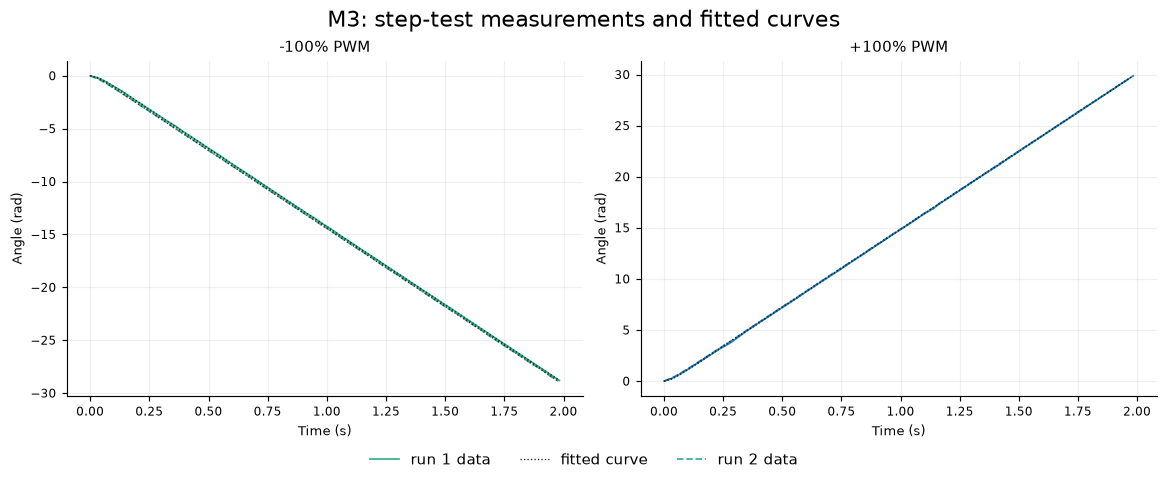

Figure: M3 step responses at -100% and +100% PWM, both repeats. Time and angle start at zero for each step. Dotted lines are the fitted curves.

Run,PWM (%),omega_ss (rad/s),Speed error estimate,Tm (s),Tm error estimate (s),Angle RMSE (rad),Note
1,-100,-13.86,0.006356,0.02149,0.0005304,0.02483,Faster than sample spacing
2,-100,-13.87,0.00438,0.02163,0.0003594,0.01781,Faster than sample spacing
1,-90,-12.59,0.01092,0.05097,0.00101,0.04141,fit
2,-90,-12.63,0.007505,0.04832,0.0006752,0.02806,fit
1,-80,-11.51,0.0081,0.07709,0.0008145,0.02846,fit
2,-80,-11.57,0.01043,0.06618,0.001073,0.03469,fit
1,-70,-10.34,0.01064,0.102,0.001193,0.03614,fit
2,-70,-10.43,0.0079,0.1099,0.0008933,0.02658,fit
1,-60,-9.336,0.008415,0.1305,0.001046,0.02599,fit
2,-60,-9.363,0.0124,0.134,0.001513,0.03853,fit


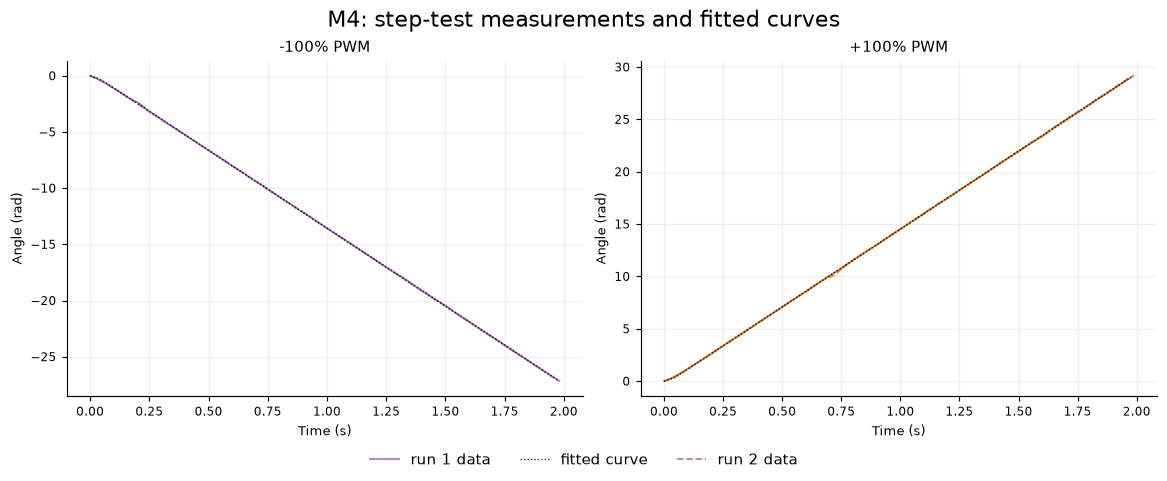

Figure: M4 step responses at -100% and +100% PWM, both repeats. Time and angle start at zero for each step. Dotted lines are the fitted curves.

In [4]:
fits=[]
for (motor,run),record in step_records.items():
    fits.extend(fit_steps(record,motor,run))
assert len(fits)==80
for motor in (3,4):
    rows=sorted([r for r in fits if r['motor']==motor],key=lambda r:(r['pwm'],r['run']))
    shown=[dict(r,T=np.nan,se_T=np.nan) if r['status']=='Time constant not measured' else r for r in rows]
    table(shown,[('run','Run'),('pwm','PWM (%)'),('speed','omega_ss (rad/s)'),
                ('se_speed','Speed error estimate'),('T','Tm (s)'),('se_T','Tm error estimate (s)'),
                ('angle_rmse','Angle RMSE (rad)'),('status','Note')],f'M{motor} step-test results')
    # Show only the two extreme power levels; all levels remain in the calculations and table.
    fig,axs=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
    for ax,pwm in zip(axs.flat,(-100,100)):
        for run,style in [(1,'-'),(2,'--')]:
            r=next(r for r in rows if r['pwm']==pwm and r['run']==run)
            s=r['segment'];color=COLORS[motor,int(np.sign(pwm))]
            ax.plot(s['t'],s['theta'],style,color=color,alpha=.8,lw=1.2,label=f'run {run} data')
            ax.plot(s['t'],angle_model(s['t'],r['speed'],r['T']),':',color='#222222',lw=.9,
                    label='fitted curve' if run==1 else None)
        ax.set_title(f'{pwm:+.0f}% PWM',fontsize=10);ax.set_xlabel('Time (s)',fontsize=9)
        ax.set_ylabel('Angle (rad)',fontsize=9);ax.tick_params(labelsize=8)
    handles,labels=axs.flat[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='outside lower center',ncol=3,frameon=False)
    fig.suptitle(f'M{motor}: step-test measurements and fitted curves',fontsize=15)
    save_figure(fig,f'step_fits_M{motor}.png',
        f'Figure: M{motor} step responses at -100% and +100% PWM, both repeats. '
        'Time and angle start at zero for each step. Dotted lines are the fitted curves.')



## Compare motor power, speed and response time

The speed table uses a straight line through the results from 40% to 100% power, separately for each direction. The slope tells how much speed increases for one extra percent of power. From it, $k_e=U_{battery}/(100\times slope)$.

That high-power trend does not pass through zero speed at zero power. The simple model needs that zero point, so it uses a separate line through zero to calculate its single speed-to-voltage value. Both sets of values are shown so the calculation is clear. The more detailed model uses the measured values at each power instead.

The error bars on the Tm plot show fitting uncertainty. An estimate faster than the time between samples is marked because its exact value is hard to measure.

Direction,Dead zone (% power),Speed increase per 1% power,ke (V s/rad),Average Tm (s),Battery voltage used (V)
Forward,Below 10%; exact value unknown,0.09859,1.156,0.175,11.4
Backward,Below 10%; exact value unknown,0.09006,1.266,0.186,11.4


Direction,Dead zone (% power),Speed increase per 1% power,ke (V s/rad),Average Tm (s),Battery voltage used (V)
Forward,Below 10%; exact value unknown,0.114,0.9911,0.134,11.3
Backward,Below 10%; exact value unknown,0.1019,1.108,0.1448,11.3


Motor,Tm used in the simple model (s),ke used in the simple model (V s/rad)
3,0.1805,0.6839
4,0.1395,0.7462


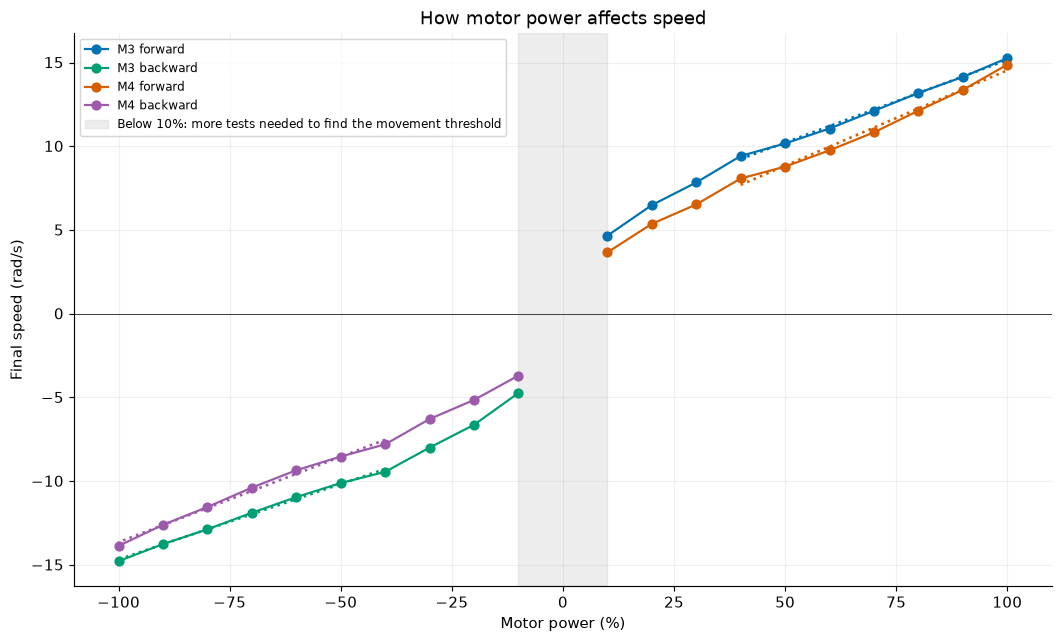

Points show the average result from the two runs. Dotted lines show the high-power trend from 40% to 100%. Both motors moved at +10% and -10%, so the exact movement threshold is below the smallest power tested.

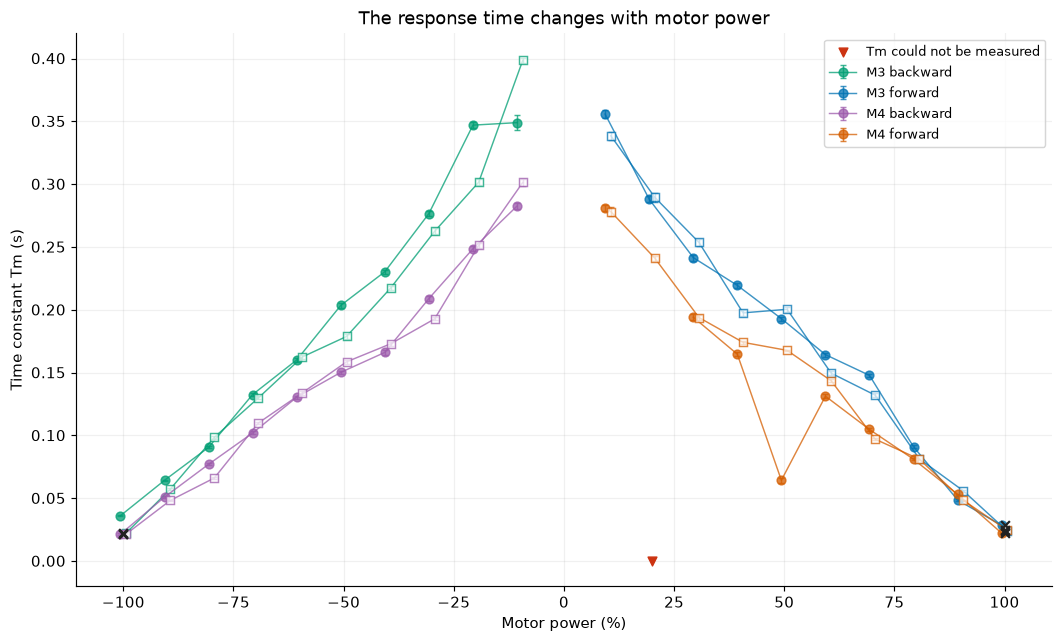

Tm is the time needed to reach about 63% of the final speed. Circles and squares show the two runs. Error bars show the fitting uncertainty. Black crosses mark changes faster than the sample spacing. The red marker means Tm was not found reliably; it does not mean the motor has zero response time.

In [5]:
summary,parameters=build_parameters(fits)
for motor in (3,4):
    table([r for r in summary if r['motor']==motor],
        [('direction','Direction'),('dead_zone','Dead zone (% power)'),('slope','Speed increase per 1% power'),
         ('ke','ke (V s/rad)'),('T_mean','Average Tm (s)'),('voltage','Battery voltage used (V)')],
        f'M{motor} results')
table([dict(motor=m,T=p['T'],ke=p['ke_simple']) for m,p in parameters.items()],
      [('motor','Motor'),('T','Tm used in the simple model (s)'),('ke','ke used in the simple model (V s/rad)')],
      'Values used for the simple model')
fig,ax=plt.subplots(figsize=(10,6),layout='constrained')
for row in summary:
    m=row['motor'];sign=1 if row['direction']=='Forward' else -1
    rows=[r for r in fits if r['motor']==m and np.sign(r['pwm'])==sign]
    powers=sorted({r['pwm'] for r in rows})
    speeds=[np.mean([r['speed'] for r in rows if r['pwm']==u]) for u in powers]
    ax.plot(powers,speeds,'o-',color=COLORS[m,sign],label=f'M{m} {row["direction"].lower()}')
    x=np.linspace(40,100,80)
    ax.plot(sign*x,sign*(row['slope']*x+row['intercept']),':',color=COLORS[m,sign],lw=1.8)
ax.axvspan(-10,10,color='#bbbbbb',alpha=.25,label='Below 10%: more tests needed to find the movement threshold')
ax.axhline(0,color='#444444',lw=.7)
ax.set(xlabel='Motor power (%)',ylabel='Final speed (rad/s)',title='How motor power affects speed')
ax.legend(fontsize=8);save_figure(fig,'speed_vs_pwm.png',
    'Points show the average result from the two runs. Dotted lines show the high-power trend from 40% to 100%. '
    'Both motors moved at +10% and -10%, so the exact movement threshold is below the smallest power tested.')
fig,ax=plt.subplots(figsize=(10,6),layout='constrained')
for motor in (3,4):
    for sign in (-1,1):
        for run,marker in [(1,'o'),(2,'s')]:
            rows=sorted([r for r in fits if r['motor']==motor and np.sign(r['pwm'])==sign and r['run']==run],key=lambda r:r['pwm'])
            x=np.array([r['pwm'] for r in rows])+(run-1.5)*1.3
            good=lambda r:r['status']!='Time constant not measured'
            ax.errorbar(x,[r['T'] if good(r) else np.nan for r in rows],
                yerr=[r['se_T'] if good(r) else np.nan for r in rows],fmt=marker+'-',
                color=COLORS[motor,sign],alpha=.75,capsize=2,lw=1,
                markerfacecolor=COLORS[motor,sign] if run==1 else 'white',
                label=f'M{motor} {"forward" if sign>0 else "backward"}' if run==1 else None)
            fast=[r for r in rows if good(r) and r['T']<r['median_dt']]
            ax.scatter([r['pwm'] for r in fast],[r['T'] for r in fast],marker='x',color='#222222',zorder=4)
            failed=[r for r in rows if not good(r)]
            if failed:ax.scatter([r['pwm'] for r in failed],[0]*len(failed),marker='v',color='#CC3311',label='Tm could not be measured',zorder=5)
ax.set(xlabel='Motor power (%)',ylabel='Time constant Tm (s)',title='The response time changes with motor power')
ax.legend(fontsize=9);save_figure(fig,'time_constant_vs_pwm.png',
    'Tm is the time needed to reach about 63% of the final speed. Circles and squares show the two runs. '
    'Error bars show the fitting uncertainty. Black crosses mark changes faster than the sample spacing. '
    'The red marker means Tm was not found reliably; it does not mean the motor has zero response time.')


## Compare the two runs

For each power, we compare the final speeds from runs 1 and 2. The percentage difference is the difference divided by the average size of the two results. Smaller differences mean the experiment is more repeatable.

Motor,Typical speed difference (%),Largest speed difference (%)
3,0.3139,4.565
4,0.6512,4.794


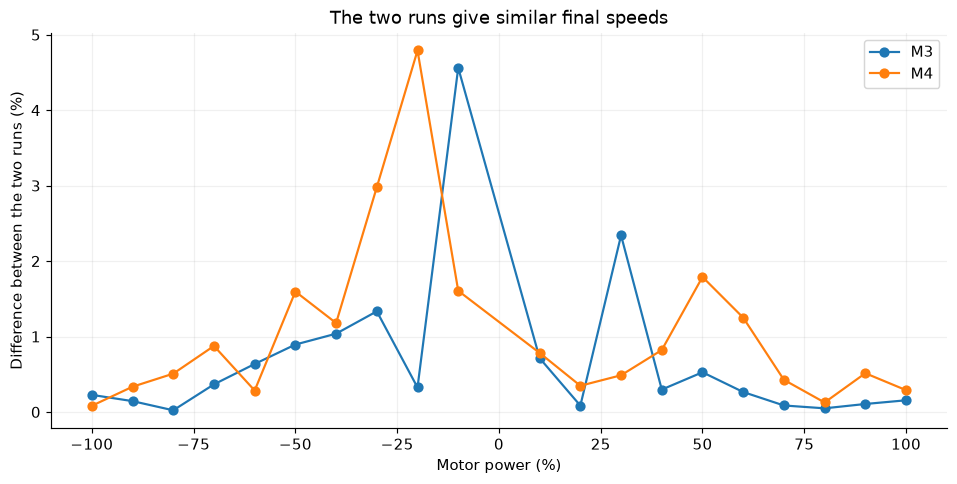

Each point compares the final speeds found for the same power in runs 1 and 2.

In [6]:
repeats=repeatability(fits)
repeat_summary=[]
for motor in (3,4):
    rows=[r for r in repeats if r['motor']==motor]
    repeat_summary.append(dict(motor=motor,
        median=float(np.median([r['speed_difference_pct'] for r in rows])),
        largest=float(max(r['speed_difference_pct'] for r in rows))))
table(repeat_summary,[('motor','Motor'),('median','Typical speed difference (%)'),
      ('largest','Largest speed difference (%)')],'Comparing run 1 with run 2')
fig,ax=plt.subplots(figsize=(9,4.5),layout='constrained')
for motor in (3,4):
    rows=[r for r in repeats if r['motor']==motor]
    ax.plot([r['pwm'] for r in rows],[r['speed_difference_pct'] for r in rows],'o-',label=f'M{motor}')
ax.set(xlabel='Motor power (%)',ylabel='Difference between the two runs (%)',title='The two runs give similar final speeds')
ax.legend();save_figure(fig,'repeatability.png','Each point compares the final speeds found for the same power in runs 1 and 2.')


## Test the models using the square wave

The square wave alternates between +60% and -60% power every half second for eight seconds. A final second records the wheel after power is removed.

The **simple model** uses one average Tm and one speed-to-voltage value for each motor. The **model using each power level** uses the step-test speed and response time for the current power. Between tested power levels, it uses values between the nearest measured points. Neither model is fitted to the square-wave recordings.

Both start with zero angle and zero speed. The first square-wave sample was taken after power was applied, so the actual speed at that instant is uncertain. We use the recorded input and times when solving the motor equations.

Measured speed is calculated from changes in angle over the recorded time intervals. To reduce small fluctuations, each speed value is averaged with its two neighbors. The same three-sample smoothing is applied to model speed.

The assignment's match score is

$$100\left(1-\frac{\|measured-predicted\|}{\|measured-mean(measured)\|}\right).$$

A score of 100% is perfect. A negative score means worse than using the average measurement. RMSE describes the typical size of an error; lower is better. All scores include the full recording, including the final slowing-down period.

Motor,Model,Angle RMSE (rad),Angle match (%),Speed RMSE (rad/s),Speed match (%)
3,Simple model,0.9614,47.63,0.9922,83.32
3,Model using each power level,0.1972,89.26,0.6854,88.47
4,Simple model,0.9722,41.19,0.5977,89.34
4,Model using each power level,0.2344,85.82,0.6133,89.07


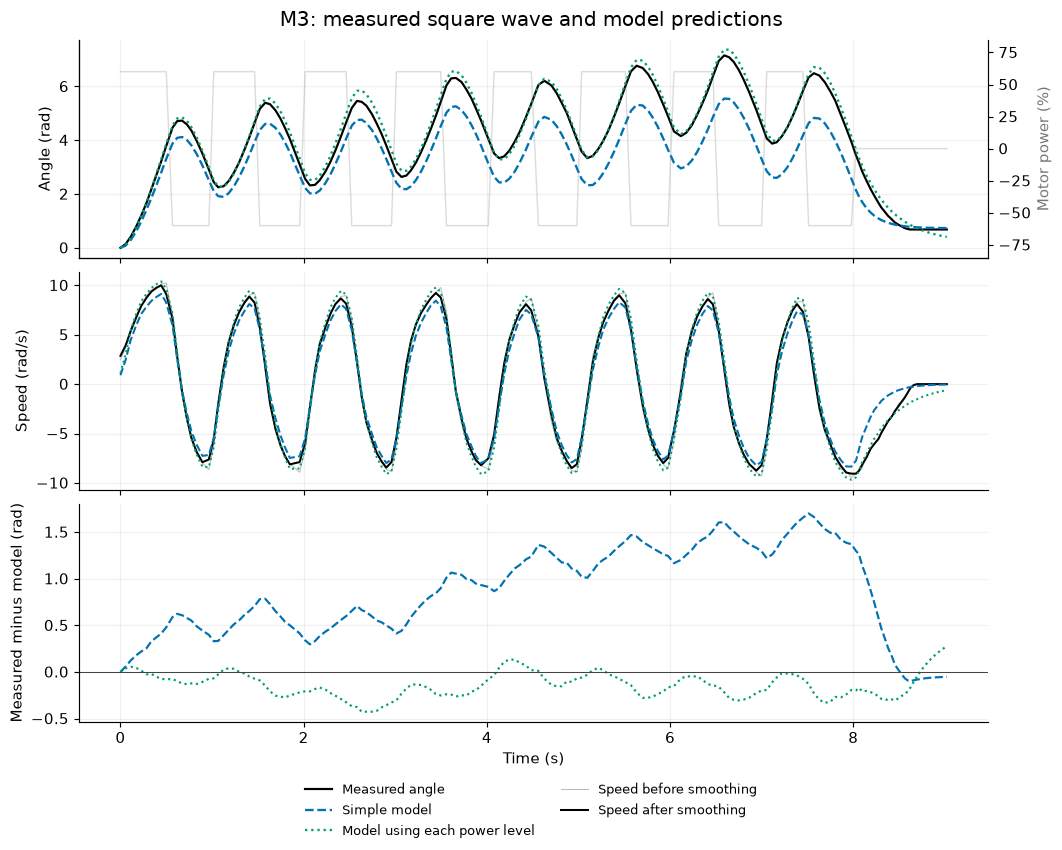

Top: wheel angle and the recorded power command. Middle: speed before and after smoothing, compared with the models. Bottom: angle error. The model values came from the step tests, not from fitting the square-wave data.

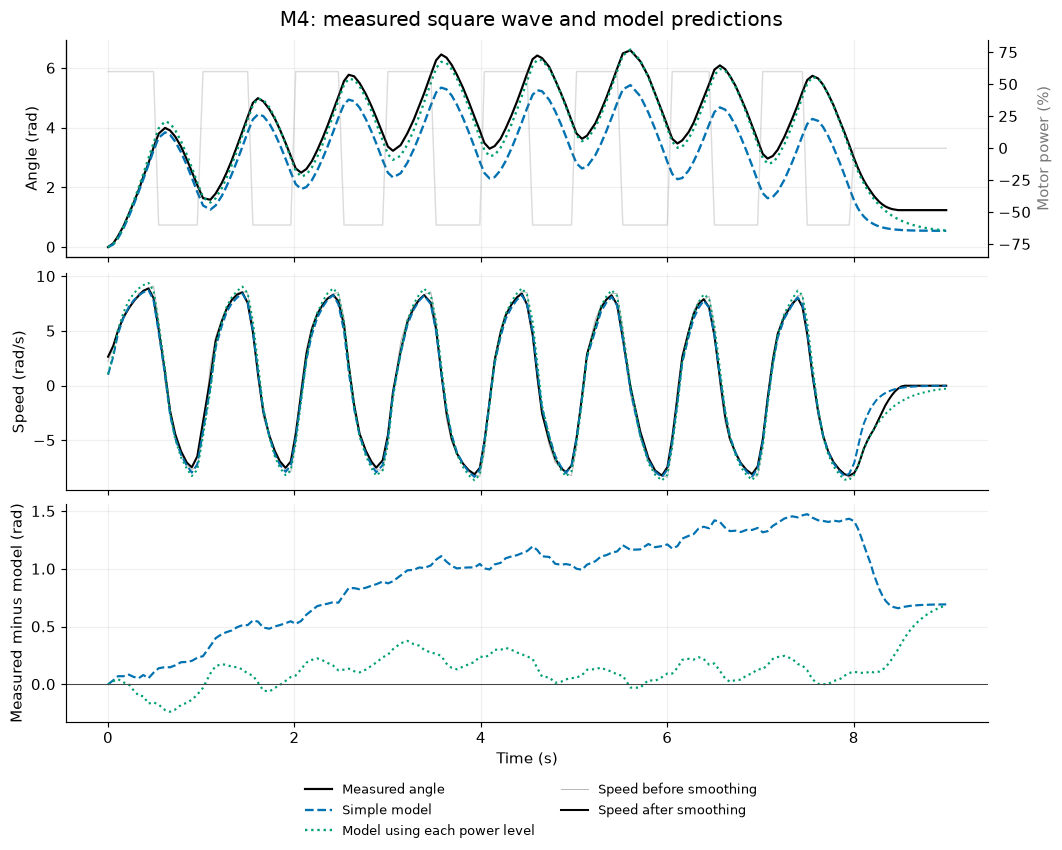

Top: wheel angle and the recorded power command. Middle: speed before and after smoothing, compared with the models. Bottom: angle error. The model values came from the step tests, not from fitting the square-wave data.

In [7]:
predictions={};metrics=[]
for (motor,kind),record in signal_records.items():
    for model in MODEL_NAMES:
        prediction=simulate(record,parameters[motor],model)
        predictions[motor,model]=prediction
        metrics.append(dict(motor=motor,model=MODEL_NAMES[model],**signal_metrics(record,prediction)))
table(metrics,[('motor','Motor'),('model','Model'),('angle_rmse','Angle RMSE (rad)'),
    ('angle_fit','Angle match (%)'),('speed_rmse_smoothed','Speed RMSE (rad/s)'),
    ('speed_fit_smoothed','Speed match (%)')],'How well the models reproduce the square wave')
for motor in (3,4):
    record=signal_records[motor,'square'];time=record['t'];angle=record['theta']
    speed=np.gradient(angle,time)
    fig,axs=plt.subplots(3,1,figsize=(10,8),sharex=True,layout='constrained')
    axs[0].plot(time,angle,'k-',label='Measured angle',lw=1.5)
    power_axis=axs[0].twinx();power_axis.spines['right'].set_visible(True)
    power_axis.plot(time,record['pwm'],color='#777777',alpha=.25,lw=1)
    power_axis.set_ylabel('Motor power (%)',color='#777777');power_axis.set_ylim(-85,85);power_axis.grid(False)
    axs[1].plot(time,speed,color='#bbbbbb',lw=.7,label='Speed before smoothing')
    axs[1].plot(time,moving_average(speed),'k-',lw=1.4,label='Speed after smoothing')
    for model,style in [('simple','--'),('power_levels',':')]:
        y=predictions[motor,model];color=MODEL_COLORS[model]
        axs[0].plot(time,y[:,1],style,color=color,label=MODEL_NAMES[model],lw=1.6)
        axs[1].plot(time,moving_average(y[:,0]),style,color=color,label=MODEL_NAMES[model],lw=1.4)
        axs[2].plot(time,angle-y[:,1],style,color=color,lw=1.5)
    axs[0].set_ylabel('Angle (rad)');axs[1].set_ylabel('Speed (rad/s)')
    axs[2].set(xlabel='Time (s)',ylabel='Measured minus model (rad)');axs[2].axhline(0,color='#444444',lw=.7)
    items={}
    for axis in axs[:2]:
        for handle,label in zip(*axis.get_legend_handles_labels()):items.setdefault(label,handle)
    fig.legend(items.values(),items.keys(),loc='outside lower center',ncol=2,fontsize=9,frameon=False)
    fig.suptitle(f'M{motor}: measured square wave and model predictions',fontsize=14)
    save_figure(fig,f'square_comparison_M{motor}.png',
        'Top: wheel angle and the recorded power command. Middle: speed before and after smoothing, compared with the models. '
        'Bottom: angle error. The model values came from the step tests, not from fitting the square-wave data.')


## Check effects visible in the measurements

We check whether the encoder changes while stopped, how far the wheel turns after power is removed, the time needed to reverse direction, and variation in sample spacing.

The encoder keeps a running count. A nonzero starting angle is therefore normal. Continued rotation after power is removed is also real movement, rather than an encoder error. Reversal delay includes the time needed to slow and reverse; these recordings cannot show how much of it comes from loose gears alone.

The supplied battery readings were taken after testing. They do not tell us how much the voltage changed during an individual run.

Motor,Run,Initial encoder (deg),Initial clock (ms),Initial zero-PWM range (deg),Net series rotation (deg)
3,1,9212,83.93,0,137
3,2,9349,82.17,0,375
4,1,5832,90.35,0,543
4,2,6375,89.81,0,475


Motor,Signal,Smallest observed angle increment (deg),Difference before/after smoothing (rad/s),Typical time covered by 3 samples (ms)
3,square,1,0.4551,111.9
4,square,1,0.47,112.9


Motor,Min coast angle (deg),Median coast angle (deg),Max coast angle (deg),Typical slowing time (s)
3,17,177.5,357,0.2729
4,18,93,197,0.1645


Motor,Square reversals,Median response delay (ms),Maximum response delay (ms)
3,15,109.7,141.7
4,15,110.9,137


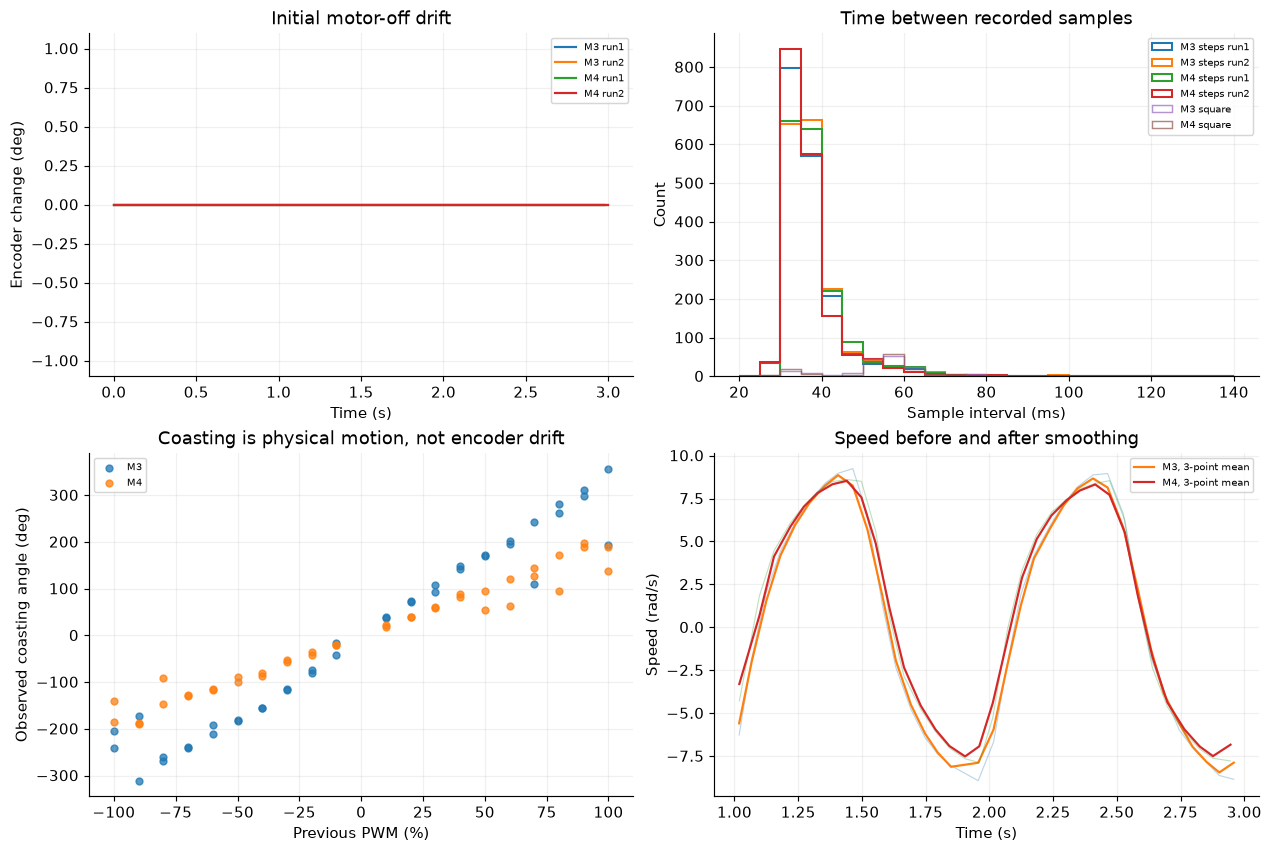

Figure: zero-drift evidence, sampling intervals, coasting angles and differentiation noise. Coasting angles exclude any unlogged motion between switching off and the first coast sample. Smoothing also changes sharp speed changes, so the difference is not entirely measurement noise.

In [8]:
coasts,reversals=coast_and_reversals(step_records,signal_records)
artifact_rows=[];noise_rows=[]
for (motor,run),record in step_records.items():
    initial=segments(record)[0]
    artifact_rows.append(dict(motor=motor,run=run,initial_angle=record['first_angle_deg'],
        initial_clock_ms=record['first_clock_ms'],zero_range_deg=float(np.rad2deg(np.ptp(initial['theta']))),
        net_angle_deg=float(np.rad2deg(record['theta'][-1]))))
for (motor,kind),record in signal_records.items():
    raw_speed=np.gradient(record['theta'],record['t']);smooth=moving_average(raw_speed)
    changes=np.diff(record['raw'][:,0]);nonzero=np.abs(changes[changes!=0])
    noise_rows.append(dict(motor=motor,signal=kind,
        residual_rms=float(np.sqrt(np.mean((raw_speed-smooth)**2))),
        min_nonzero_angle_step=float(nonzero.min()),
        median_window_span_ms=float(np.median(record['t'][2:]-record['t'][:-2])*1000)))
table(artifact_rows,[('motor','Motor'),('run','Run'),('initial_angle','Initial encoder (deg)'),
      ('initial_clock_ms','Initial clock (ms)'),('zero_range_deg','Initial zero-PWM range (deg)'),
      ('net_angle_deg','Net series rotation (deg)')],'Encoder readings while stopped')
table(noise_rows,[('motor','Motor'),('signal','Signal'),('min_nonzero_angle_step','Smallest observed angle increment (deg)'),
      ('residual_rms','Difference before/after smoothing (rad/s)'),('median_window_span_ms','Typical time covered by 3 samples (ms)')],
      'Small encoder changes and speed smoothing')
coast_summary=[];reversal_summary=[]
for m in (3,4):
    cc=[r for r in coasts if r['motor']==m];tt=[r['T_coast'] for r in cc if np.isfinite(r['T_coast'])]
    coast_summary.append(dict(motor=m,coast_angle_min=float(min(abs(r['angle_deg']) for r in cc)),
        coast_angle_median=float(np.median([abs(r['angle_deg']) for r in cc])),
        coast_angle_max=float(max(abs(r['angle_deg']) for r in cc)),
        median_coast_T=float(np.median(tt)) if tt else np.nan))
    rev=[r['response_delay_s'] for r in reversals if r['motor']==m and np.isfinite(r['response_delay_s'])]
    reversal_summary.append(dict(motor=m,events=len(rev),median_delay_ms=float(np.median(rev)*1000),
        max_delay_ms=float(max(rev)*1000)))
table(coast_summary,[('motor','Motor'),('coast_angle_min','Min coast angle (deg)'),
      ('coast_angle_median','Median coast angle (deg)'),('coast_angle_max','Max coast angle (deg)'),
      ('median_coast_T','Typical slowing time (s)')],'Wheel movement after power was removed')
table(reversal_summary,[('motor','Motor'),('events','Square reversals'),('median_delay_ms','Median response delay (ms)'),
      ('max_delay_ms','Maximum response delay (ms)')],'Time taken to change rotation direction')
fig,axs=plt.subplots(2,2,figsize=(12,8),layout='constrained')
for (m,run),record in step_records.items():
    s=segments(record)[0]
    axs[0,0].plot(s['t'],np.rad2deg(s['theta']),label=f'M{m} run{run}')
    axs[0,1].hist(np.diff(record['t'])*1000,bins=np.arange(20,141,5),histtype='step',lw=1.4,
                  label=f'M{m} steps run{run}')
for m in (3,4):
    for kind in ('square',):
        r=signal_records[m,kind]
        axs[0,1].hist(np.diff(r['t'])*1000,bins=np.arange(20,141,5),histtype='step',lw=1,
                      alpha=.7,label=f'M{m} {kind}')
    cc=[r for r in coasts if r['motor']==m]
    axs[1,0].scatter([r['pwm'] for r in cc],[r['angle_deg'] for r in cc],s=22,label=f'M{m}',alpha=.75)
    r=signal_records[m,'square'];v=np.gradient(r['theta'],r['t']);mask=(r['t']>1)&(r['t']<3)
    axs[1,1].plot(r['t'][mask],v[mask],alpha=.3,lw=.8)
    axs[1,1].plot(r['t'][mask],moving_average(v)[mask],lw=1.5,label=f'M{m}, 3-point mean')
axs[0,0].set(xlabel='Time (s)',ylabel='Encoder change (deg)',title='Initial motor-off drift');axs[0,0].set_ylim(-1.1,1.1)
axs[0,1].set(xlabel='Sample interval (ms)',ylabel='Count',title='Time between recorded samples')
axs[1,0].set(xlabel='Previous PWM (%)',ylabel='Observed coasting angle (deg)',title='Coasting is physical motion, not encoder drift')
axs[1,1].set(xlabel='Time (s)',ylabel='Speed (rad/s)',title='Speed before and after smoothing')
for ax in axs.flat:ax.legend(fontsize=7)
save_figure(fig,'artifact_evidence.png','Figure: zero-drift evidence, sampling intervals, coasting angles and differentiation noise. '
    'Coasting angles exclude any unlogged motion between switching off and the first coast sample. '
    'Smoothing also changes sharp speed changes, so the difference is not entirely measurement noise.')



# Motor identification results

The repeated step tests give similar final speeds. A model that uses the measured values at each motor power follows the square wave more closely than a model using one average set of values.

## Motor values

Tm is the time needed to reach about 63% of the final speed. ke describes how much voltage the model needs for one unit of speed. Speeds are measured in radians per second; one full turn is about 6.28 radians.

| Motor | Direction | Speed increase per 1% power (rad/s) | ke (V s/rad) | Average Tm (s) | Battery reading used (V) |
|---|---|---:|---:|---:|---:|
| M3 | Forward | 0.0986 | 1.156 | 0.175 | 11.4 |
| M3 | Backward | 0.0901 | 1.266 | 0.186 | 11.4 |
| M4 | Forward | 0.1140 | 0.991 | 0.134 | 11.3 |
| M4 | Backward | 0.1019 | 1.108 | 0.145 | 11.3 |

These ke values come from the speed trend between 40% and 100% power. The simple model needs speed to be zero at zero power, so it uses a separate line through zero. That gives ke values of 0.684 for M3 and 0.746 for M4. The notebook shows the calculations.

## Square-wave comparison

The square wave alternates between +60% and -60% power every half second. The models use values found from the step tests; they are not fitted to the square-wave recordings.

A match of 100% is perfect. RMSE describes the typical size of the angle error; a smaller value is better. The scores below include the final second after power is removed.

| Motor | Model | Angle match (%) | Angle RMSE (rad) | Speed match after smoothing (%) |
|---|---|---:|---:|---:|
| M3 | Simple model | 47.6 | 0.961 | 83.3 |
| M3 | Model using each power level | 89.3 | 0.197 | 88.5 |
| M4 | Simple model | 41.2 | 0.972 | 89.3 |
| M4 | Model using each power level | 85.8 | 0.234 | 89.1 |

## Discussion

**How well the model works.** The fitted curves closely follow the individual step recordings: the middle angle error across the 80 tests is 0.032 rad, or about 1.85 degrees. However, response time changes with motor power, so one average Tm and ke does not describe every movement. Using the speed and response time measured at each power improves the square-wave angle match to 89.3% for M3 and 85.8% for M4. The error plots show where the models differ from the measurements, including after power is removed. This result applies to the tested square wave; it does not prove that the model will predict every possible movement.

**Forward and backward rotation.** The speed-versus-power slopes differ by 9.0% between directions for M3 and 11.2% for M4. The two motors also reach different speeds at the same power. A controller should use separate settings for each motor and account for direction, rather than assume both wheels behave identically. A useful controller would also account for the response time changing with power. The measurements were made with the wheels lifted, so these values describe freely spinning wheels without load.

**Measurement effects and distance estimation.** The repeated final speeds differ by a middle value of 0.31% for M3 and 0.65% for M4. The initial motor-off records show no encoder change. The wheels still turn after power is removed: the middle measured amounts are 177.5 degrees for M3 and 93.0 degrees for M4. The smallest recorded encoder change is one degree, and the time between samples is longer and less regular than the requested 5 ms delay. These effects matter when estimating travel distance and turning angle. The direction-change delay cannot be attributed to loose gears alone, because the wheel also needs time to slow and reverse.

**Why the square wave was useful.** A step starts with a stationary wheel and holds one power. The square wave repeatedly changes direction before the wheel has been stopped for a full second. It therefore tests how the model handles slowing down, reversing and speeding up again. The comparison reveals differences that are not obvious from the step plots alone. The measured speed was calculated from angle and the recorded times, then smoothed using the average of three nearby samples. The same smoothing was applied to model speed for a fair comparison; the original recordings were kept unchanged.

## Limits to keep in mind

- Both motors moved at +10% and -10% power. The exact dead zone, meaning the power range where the motor does not move, is therefore below the smallest tested power and has not been measured precisely.
- One M4 test at +20% did not show a response time that could be measured reliably. It is marked in the results and omitted when averaging Tm. Its final speed is still used.
- At high power, some estimated response times are shorter than the gap between samples. Their exact values are uncertain.
- Speed continued to increase through 100% power; no clear speed limit was reached in the tested range.
- Battery readings were taken before testing: 11.4 V for the M3 step tests and both square waves, and 11.3 V for the M4 step pair. Using these readings for the earlier samples is an approximation.
